# Every command, on one dataset

A runnable tour of Polariseq: every public function, each with a short example on the 10x Genomics
PBMC 3k dataset (2,700 blood cells, downloaded once, about 8 MB). Run the cells in order; each one
builds on the ones before.

The full list of functions, with every argument, its type and default, is in
[`docs/API.md`](../docs/API.md) (`help(ps.pp.pca)` shows the same for one function).

| part | what |
|---|---|
| 1 | project folder, memory budget, planning |
| 2 | reading data, the data object and its attributes |
| 3 | quality control and doublets |
| 4 | normalization, gene selection (with genes of your own), PCA |
| 5 | batch integration |
| 6 | neighbour graph, clusters, UMAP, hierarchy, PAGA, pseudotime |
| 7 | marker genes, scores, annotation, curating clusters |
| 8 | comparing conditions with donors as replicates |
| 9 | several analyses with different settings, and how far they agree |
| 10 | saving, loading, exporting |
| 11 | out of core, and the one-call pipeline |
| 12 | figures for a whole analysis, themes, and what errors look like |

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import polariseq as ps

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "examples"))
from _data import fetch_pbmc3k  # the examples' download helper

ps.pl.set_theme("notebook")     # larger type for a notebook; "paper" is the default
print(ps.__version__, ps.get_build_info())

0.2.0 {'python_version': '0.2.0', 'rust_core_version': '0.2.0', 'matched': True}


## 1. Project folder, budget, planning

**`ps.project(folder)`** declares where everything Polariseq writes goes: on-disk copies of the
counts, results (as memory-mapped files), saved analyses. Declare it first.

**`ps.set_budget(ram_gb=, threads=)`** sets the memory and threads Polariseq may use. It decides
whether an analysis runs in memory or out of core and how large the blocks are; set it before the
first step (the thread pool cannot change size later). **`ps.resources()`** shows the machine,
**`ps.budget()`** the active budget, **`ps.workflow()`** the active defaults (`'polariseq'` or
`'scanpy'`, see `ps.set_workflow`).

In [2]:
proj = ps.project(ROOT / "examples" / "output" / "project_notebook")
ps.set_budget(ram_gb=4, threads=4)
print(ps.resources())
print(ps.budget())
print("workflow:", ps.workflow())
proj

Resources(ram=8.6 GB total, 1.3 GB available [psutil], cores=4P/8, spill=16 GB free at ~/polariseq/examples/output/project_notebook/scratch)
Budget(ram=4.0 GB, threads=4, spill=15 GB at ~/polariseq/examples/output/project_notebook/scratch, exact only)
workflow: polariseq


Project('~/polariseq/examples/output/project_notebook', runs=['pbmc3k', 'pbmc3k_ooc'])

## 2. Reading data, and the data object

Readers: **`ps.read_h5ad`** (one file, several files as one dataset, `mode="memory"` or
`"out-of-core"`), **`ps.read_10x_h5`**, **`ps.read_10x_mtx`**. They return at once; the matrix is
read on first use. Here the 10x folder is written once as an `.h5ad` with **`write_h5ad`**: saved
analyses point back to `.h5ad` sources.

In [3]:
tenx = ps.read_10x_mtx(str(fetch_pbmc3k()))
print(tenx)                                   # lazy: nothing read yet
src = proj.path / "data" / "pbmc3k.h5ad"
if not src.exists():
    src.parent.mkdir(parents=True, exist_ok=True)
    tenx.write_h5ad(src)                      # the raw counts, as an .h5ad

LazyAnnData(n_obs=2,700, n_vars=32,738, format=10x_mtx, mode=memory, lazy (~0.0 GB on materialize))


**`ps.plan(path)`** predicts each step's peak memory and the disk a run will use, from the file's
metadata alone. **`ps.max_cells()`** answers the reverse question: how many cells fit this budget.

In [4]:
p = ps.plan(str(src), n_hvg=2000, n_pcs=30)
print(f"fits: {p.fits}, peak {p.peak_gb:.2f} GB, limiting step: {p.limiting_step}")
print(f"at most {ps.max_cells(n_genes=33_000, nnz_per_cell=850):,} cells of this density fit in memory")

2,700 cells x 32,738 genes, 2,286,884 nonzeros
storage: ram   budget: 4.0 GB RAM, 4 threads   block: 32,768 rows
  load               1.118 GB
  qc                 0.322 GB
  normalize+log1p    0.320 GB   in place
  hvg                0.349 GB   gene statistics
  hvg subset         0.349 GB   original + 2000-gene subset both alive, renormalized through views
  pca                0.625 GB   exact Gram (2000^2 f64, 1 partial sums kept until merged, + eigen workspace)
  neighbors          0.306 GB   NN-Descent forest at 4 threads; embedding read into memory (0.00 GB)
  leiden             0.307 GB   graph read into memory (0.00 GB)
  umap               0.308 GB   graph read into memory (0.00 GB)
peak 1.12 GB at 'load' — fits
  project folder at most 0.0 GB: results 0.0
fits: True, peak 1.12 GB, limiting step: load
at most 1,452,359 cells of this density fit in memory


In [5]:
adata = ps.read_h5ad(str(src))
print(adata)
print("mode:", adata.mode, "| name:", adata.name, "| shape:", adata.shape)
print("first cells:", adata.obs_names[:3], "| first genes:", adata.var_names[:3])
print("a preview of 3 cells' raw values:", {k: v for k, v in adata.head(3).items() if k.startswith("n_")})
print(adata.validate())

LazyAnnData(n_obs=2,700, n_vars=32,738, format=h5ad, mode=memory, lazy (~0.0 GB on materialize))
mode: memory | name: pbmc3k | shape: (2700, 32738)
first cells: ['AAACATACAACCAC-1', 'AAACATTGAGCTAC-1', 'AAACATTGATCAGC-1'] | first genes: ['MIR1302-10', 'FAM138A', 'OR4F5']
a preview of 3 cells' raw values: {'n_cells': 3, 'n_genes': 32738}
{'path': '~/polariseq/examples/output/project_notebook/data/pbmc3k.h5ad', 'format': 'h5ad', 'exists': True, 'size_mb': 20.156365, 'n_obs': 2700, 'n_vars': 32738, 'nnz': 2286884, 'sparsity': 0.9741281057464086, 'encoding': 'csr', 'est_ram_gb': 0.018295072, 'scan_time_s': 0.010583833005512133}


The data object holds the matrix **`X`**, per-cell **`obs`** and per-gene **`var`** (dicts of
arrays), embeddings **`obsm`**, graphs **`obsp`**, and each step's records **`uns`**. Subset with
`adata[cells]` or `adata[cells, genes]` (a mask, positions or names); the result is a new object.

In [6]:
first_hundred = adata[:100]
some_genes = adata[:, ["CD3E", "MS4A1", "CD14"]]
print(first_hundred.shape, some_genes.shape, type(some_genes.X).__name__)

[polariseq] Materializing pbmc3k.h5ad (2,700 × 32,738, ~0.0 GB)...
[polariseq] Ready in 0.0s
(100, 32738) (2700, 3) SparseMatrix


## 3. Quality control and doublets

**`ps.pp.calculate_qc_metrics`** adds `n_counts`, `n_genes` and `pct_counts_mt` per cell.
**`ps.pp.scrublet`** scores doublets from the raw counts (pass `batch_key=` with the column of the
capture, the 10x channel, when there are several). Filter with **`ps.pp.filter_cells`** and
**`ps.pp.filter_genes`**; drop called doublets by subsetting.

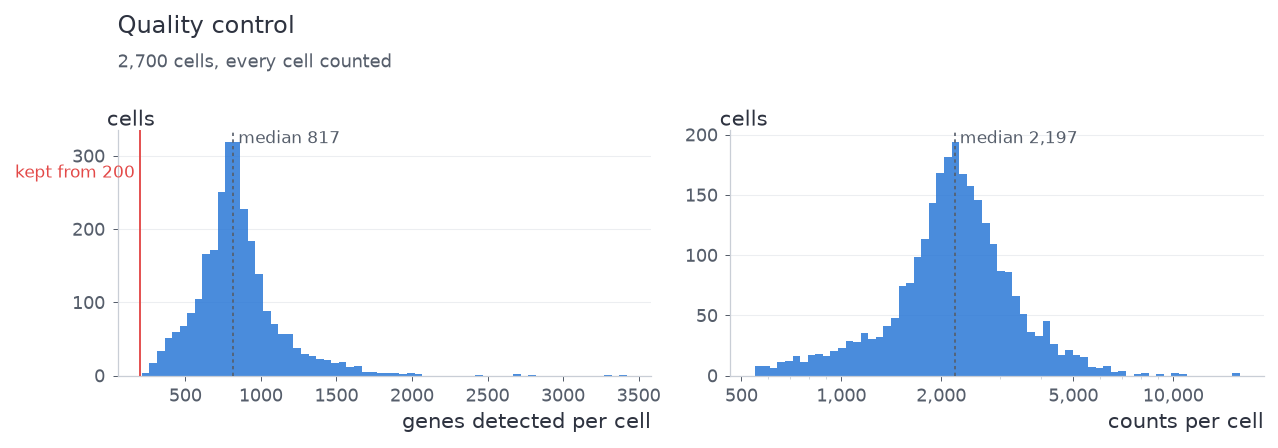

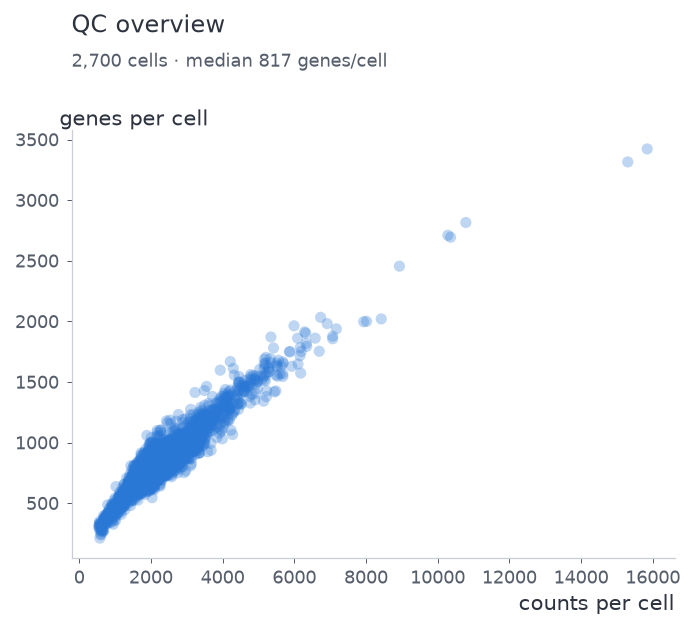

<Axes: title={'left': 'QC overview'}, xlabel='counts per cell', ylabel='genes per cell'>

In [7]:
ps.pp.calculate_qc_metrics(adata, mito_prefix="MT-")
qc_before = {k: np.asarray(adata.obs[k]).copy() for k in ("n_genes", "n_counts")}
ps.pl.qc_distributions(adata, keys=("n_genes", "n_counts"), thresholds={"n_genes": 200})
ps.pl.scatter_qc(adata)

37 doublets called


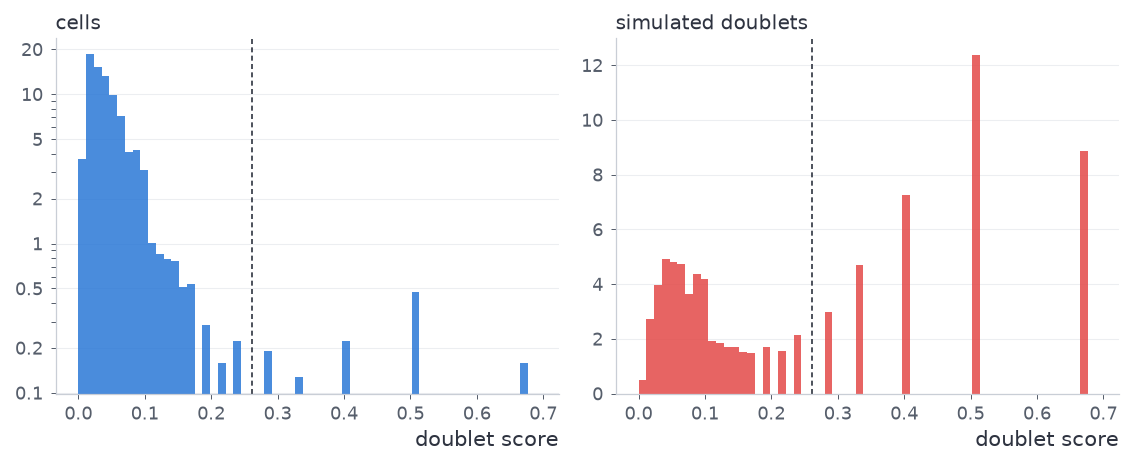

array([[<Axes: title={'left': 'cells'}, xlabel='doublet score'>,
        <Axes: title={'left': 'simulated doublets'}, xlabel='doublet score'>]],
      dtype=object)

In [8]:
ps.pp.scrublet(adata)
print(f"{int(np.sum(adata.obs['predicted_doublet']))} doublets called")
ps.pl.scrublet_score_distribution(adata)

In [9]:
ps.pp.filter_cells(adata, min_genes=200, max_pct_mt=5)
adata = adata[~np.asarray(adata.obs["predicted_doublet"], dtype=bool)]
ps.pp.filter_genes(adata, min_cells=3)
adata.shape

Filtered out 57 cells (2,643 remaining)


Filtered out 19093 genes (13,645 remaining)


(2606, 13645)

## 4. Normalization, gene selection, PCA

**`normalize_total`** then **`log1p`**. **`highly_variable_genes`** ranks genes; `include=` keeps genes
you study whatever the ranking chooses (added to the top `n_top_genes`, marked in `var['included']`);
`subset=True` keeps only the selected genes. **`renormalize`** normalizes each cell again over them
(Polariseq's default recipe). **`pca`** with `scale=True` standardizes each gene first.

added to the ranking's choice: ['CD8A', 'CD3E', 'CD14']


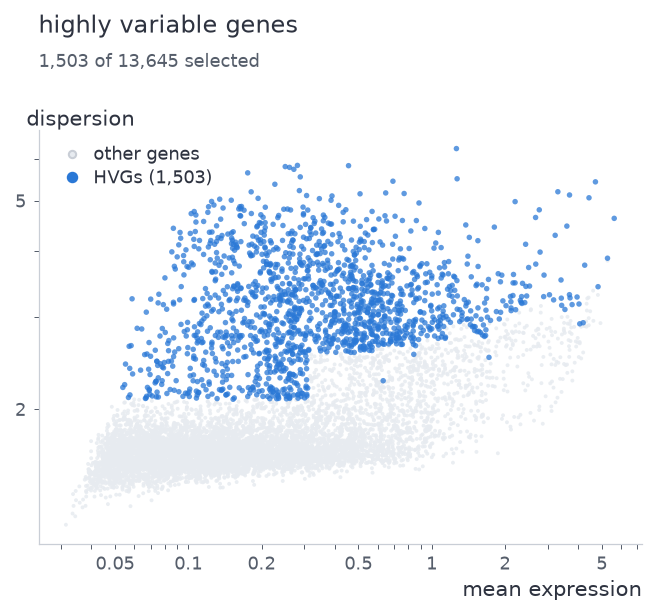

<Axes: title={'left': 'highly variable genes'}, xlabel='mean expression', ylabel='dispersion'>

In [10]:
ps.pp.normalize_total(adata, target_sum=1e4)
ps.pp.log1p(adata)
my_genes = ["FCER1A", "PPBP", "CD8A", "CD3E", "CD14"]   # the marker panel below needs them
ps.pp.highly_variable_genes(adata, n_top_genes=1500, include=my_genes)
print("added to the ranking's choice:", adata.uns["hvg"]["include_added"])
ps.pl.highly_variable_genes(adata)

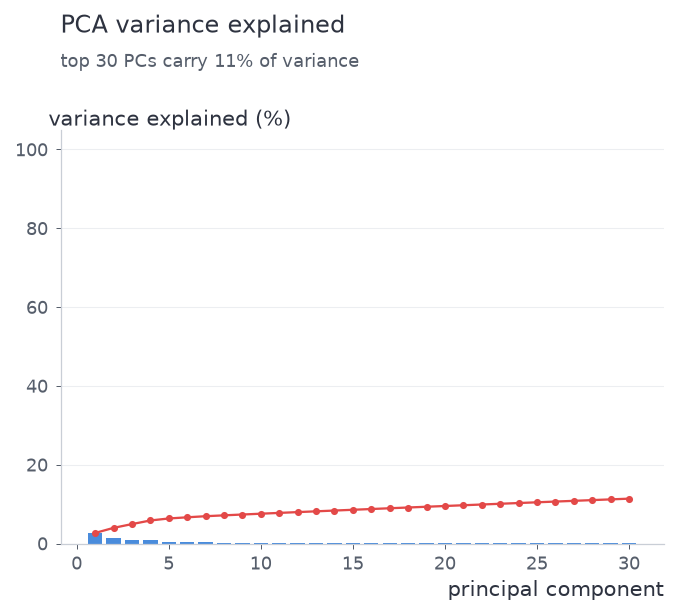

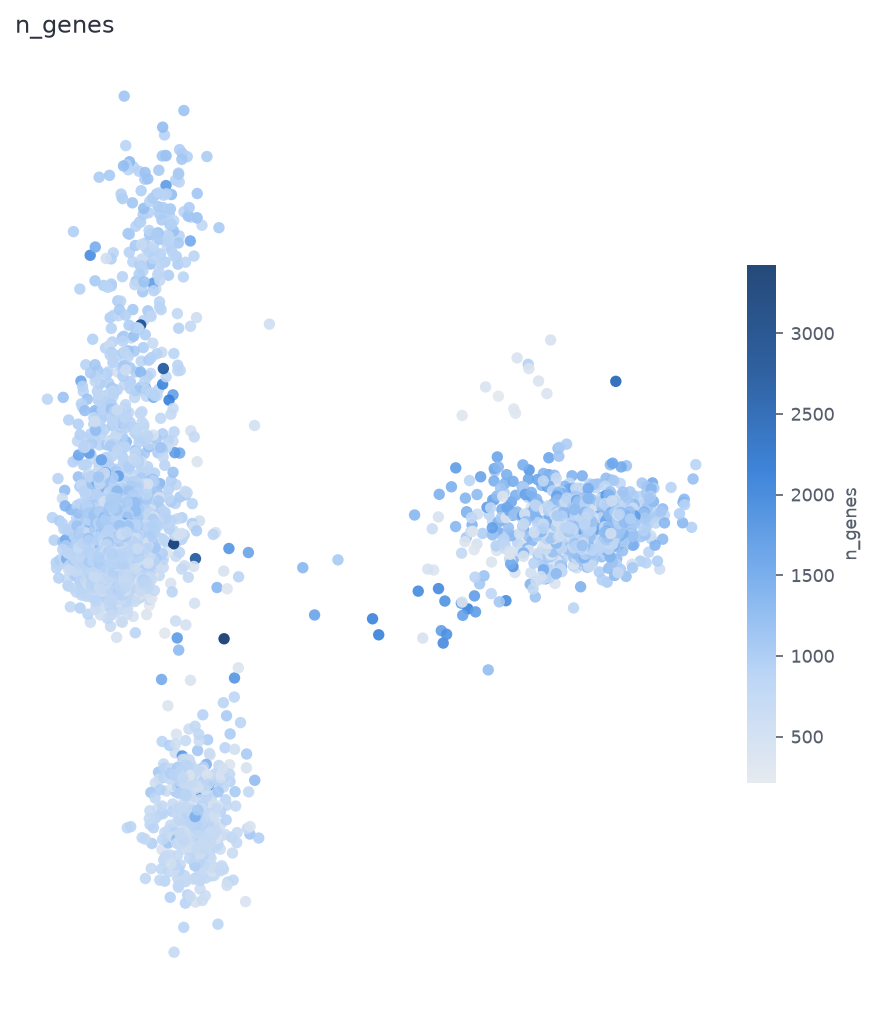

<Axes: title={'left': 'n_genes'}>

In [11]:
ps.pp.highly_variable_genes(adata, n_top_genes=1500, include=my_genes, subset=True)
ps.pp.renormalize(adata)
ps.pp.pca(adata, n_components=30, scale=True, seed=0)
ps.pl.pca_variance_ratio(adata, n_comps=30)
ps.pl.pca(adata, color="n_genes")

## 5. Batch integration

**`ps.pp.harmony_integrate(adata, batch_key)`** corrects the PCA embedding for batches (patients,
lanes, studies) and writes `obsm['X_pca_harmony']`; build the graph on it with
`neighbors(use_rep="X_pca_harmony")`. PBMC 3k is one batch, so a made-up column shows the call.

In [12]:
rng = np.random.default_rng(0)
adata.obs["batch"] = pd.Categorical(rng.choice(["lane1", "lane2"], adata.n_obs))
ps.pp.harmony_integrate(adata, "batch")
print(list(adata.obsm))

['X_pca', 'X_pca_harmony']


## 6. Graph, clusters, embedding, hierarchy

**`neighbors`** builds the kNN graph, **`leiden`** clusters it (`resolution=`: higher gives more
clusters), **`umap`** lays it out. **`paris`** builds a cluster hierarchy and cuts it,
**`paga`** joins clusters into a coarse graph, **`dpt`** orders cells by graph distance from a root.

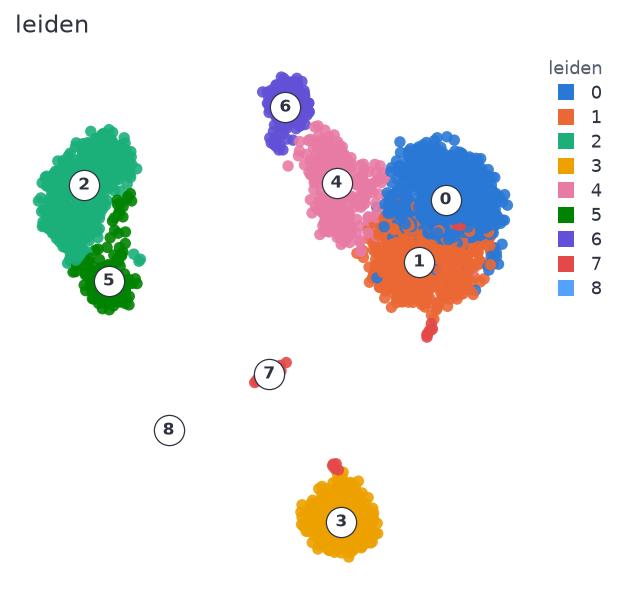

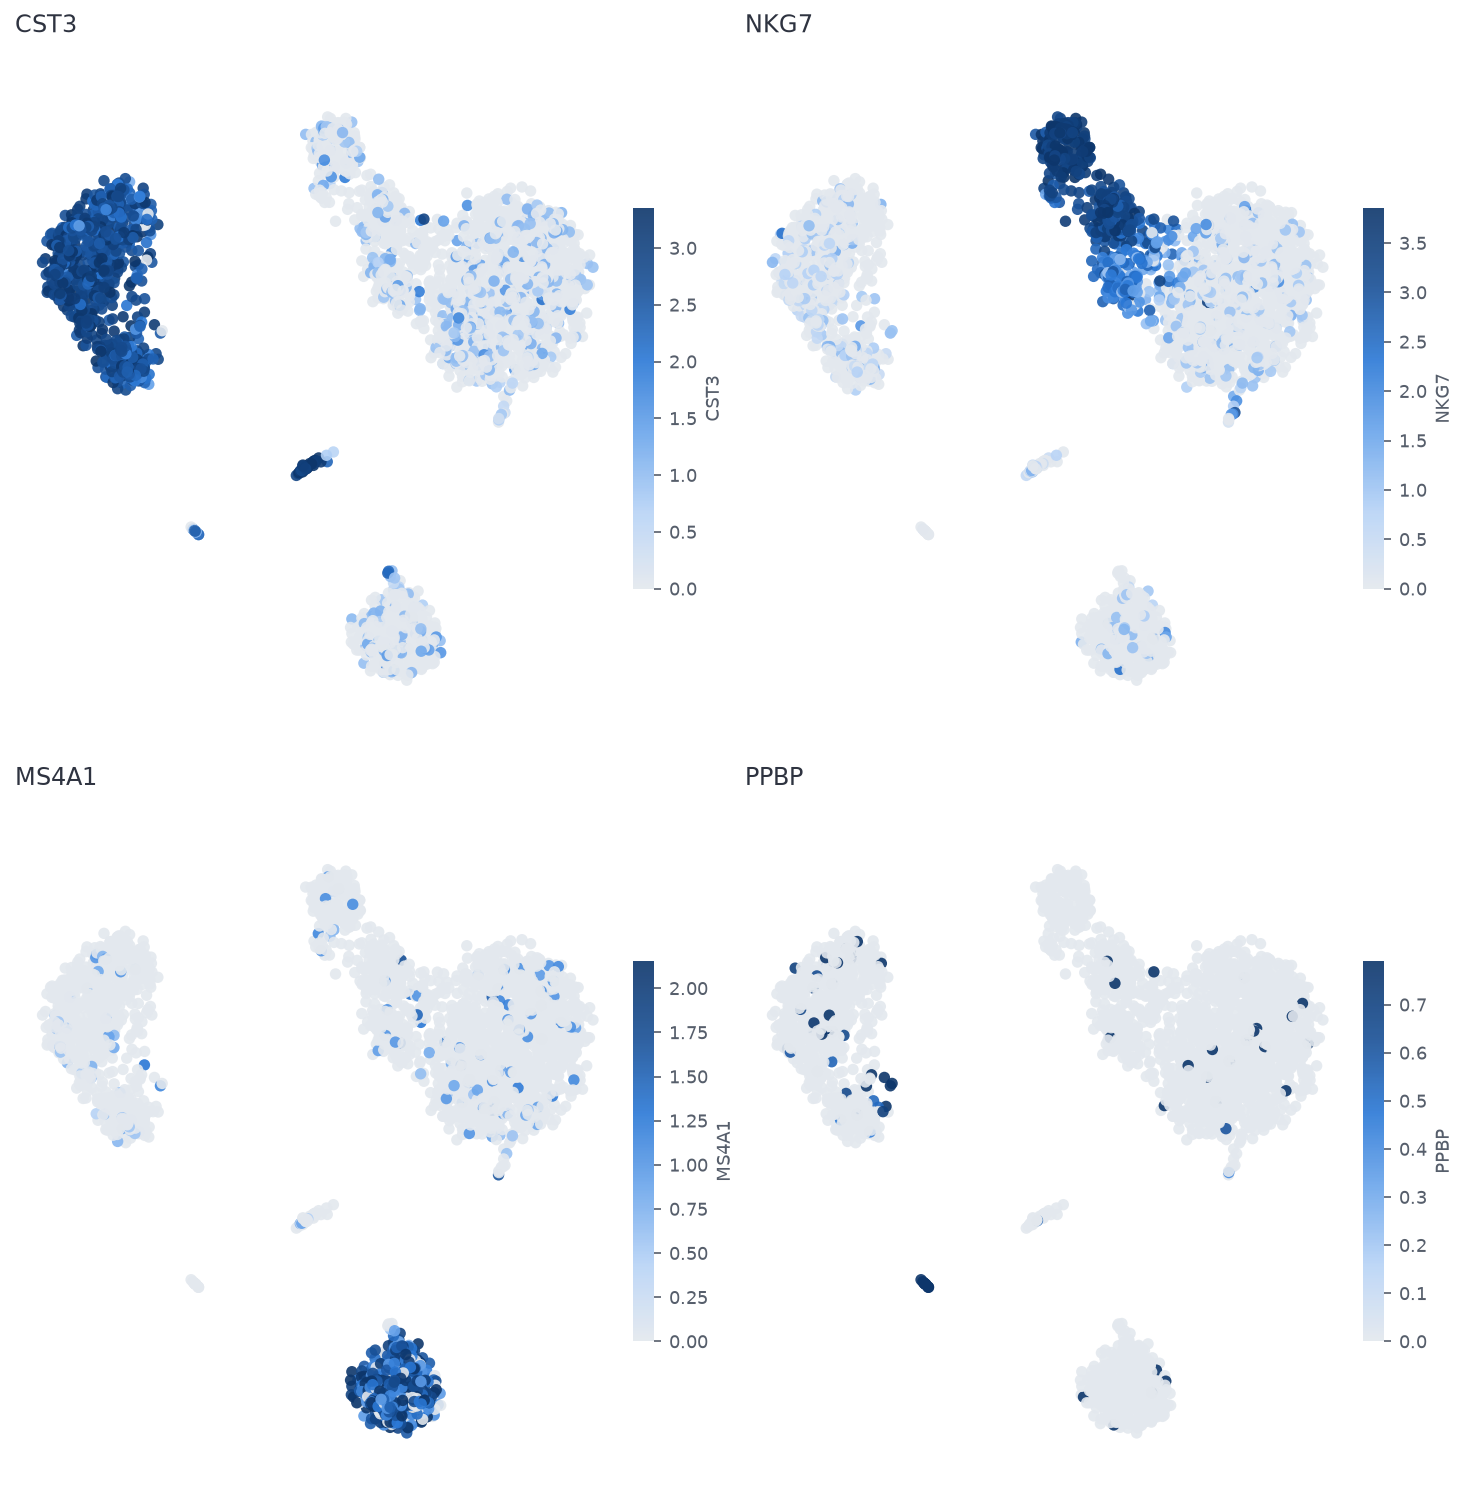

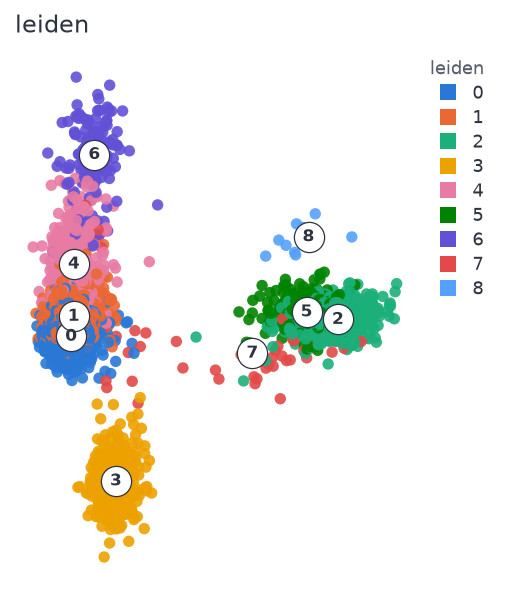

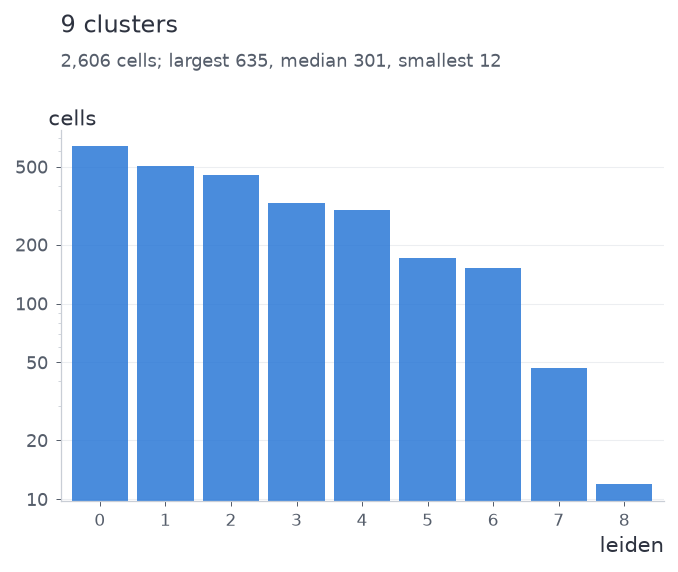

<Axes: title={'left': '9 clusters'}, xlabel='leiden', ylabel='cells'>

In [13]:
ps.pp.neighbors(adata, n_neighbors=15, seed=0)
ps.tl.leiden(adata, resolution=1.0, seed=0)
ps.tl.umap(adata, seed=0)
ps.pl.umap(adata, color="leiden")
ps.pl.umap(adata, color=["CST3", "NKG7", "MS4A1", "PPBP"])
ps.pl.embedding(adata, basis="X_pca", color="leiden")
ps.pl.cluster_sizes(adata, key="leiden")

paris clusters: [0, 1, 2, 3, 4, 5]
PAGA graph: (9, 9)


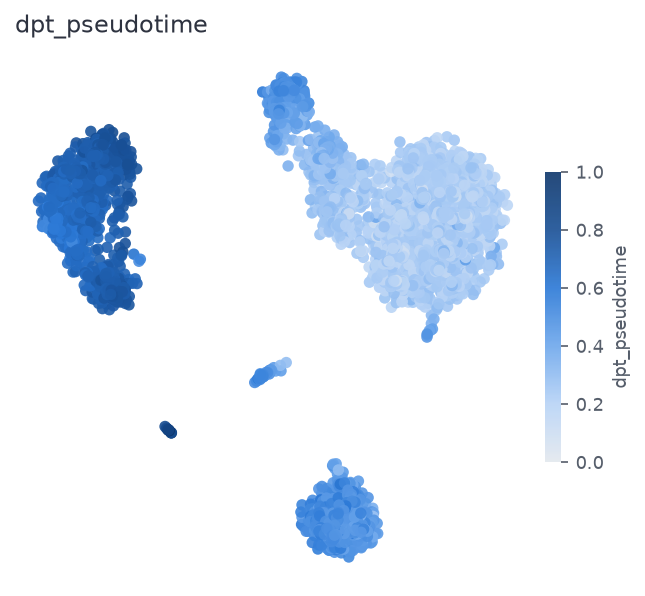

<Axes: title={'left': 'dpt_pseudotime'}>

In [14]:
ps.tl.paris(adata, n_clusters=6)
ps.tl.paga(adata, groupby="leiden")
ps.tl.dpt(adata, root=0)
print("paris clusters:", sorted(set(np.asarray(adata.obs["paris"]).tolist())))
print("PAGA graph:", adata.uns["paga"]["connectivities"].shape)
ps.pl.umap(adata, color="dpt_pseudotime")

## 7. Markers, scores, annotation, curation

**`rank_genes_groups`** finds each cluster's markers; **`ps.get.markers`** gives them as a table.
**`score_genes`** scores a gene set per cell. **`auto_annotate`** names clusters from marker databases
(PanglaoDB, a curated set, or CellTypist). Curate by hand with **`annotate`** (name clusters),
**`merge_clusters`** and **`subcluster`**.

`auto_annotate` is a first guess, to check against the marker table: here it names the CD14+
monocytes (LYZ, CST3, CD14 in the dot plot) "Dendritic cells", two types that share many PanglaoDB
markers. `annotate` corrects such a call by hand.

In [15]:
ps.tl.rank_genes_groups(adata, groupby="leiden", n_genes=50)
ps.get.markers(adata, n=4, wide=True)

,0,1,2,3,4,5,6,7,8
0,MALAT1,LTB,LYZ,CD74,CCL5,FTH1,NKG7,HLA-DRB1,GPX1
1,RPL13,IL32,FTL,HLA-DRA,NKG7,FTL,GNLY,CD74,SDPR
2,RPS27A,TPT1,TYROBP,HLA-DPB1,B2M,AIF1,GZMB,HLA-DRB5,PF4
3,RPS3A,B2M,CST3,HLA-DRB1,IL32,LST1,CTSW,HLA-DRA,PPBP


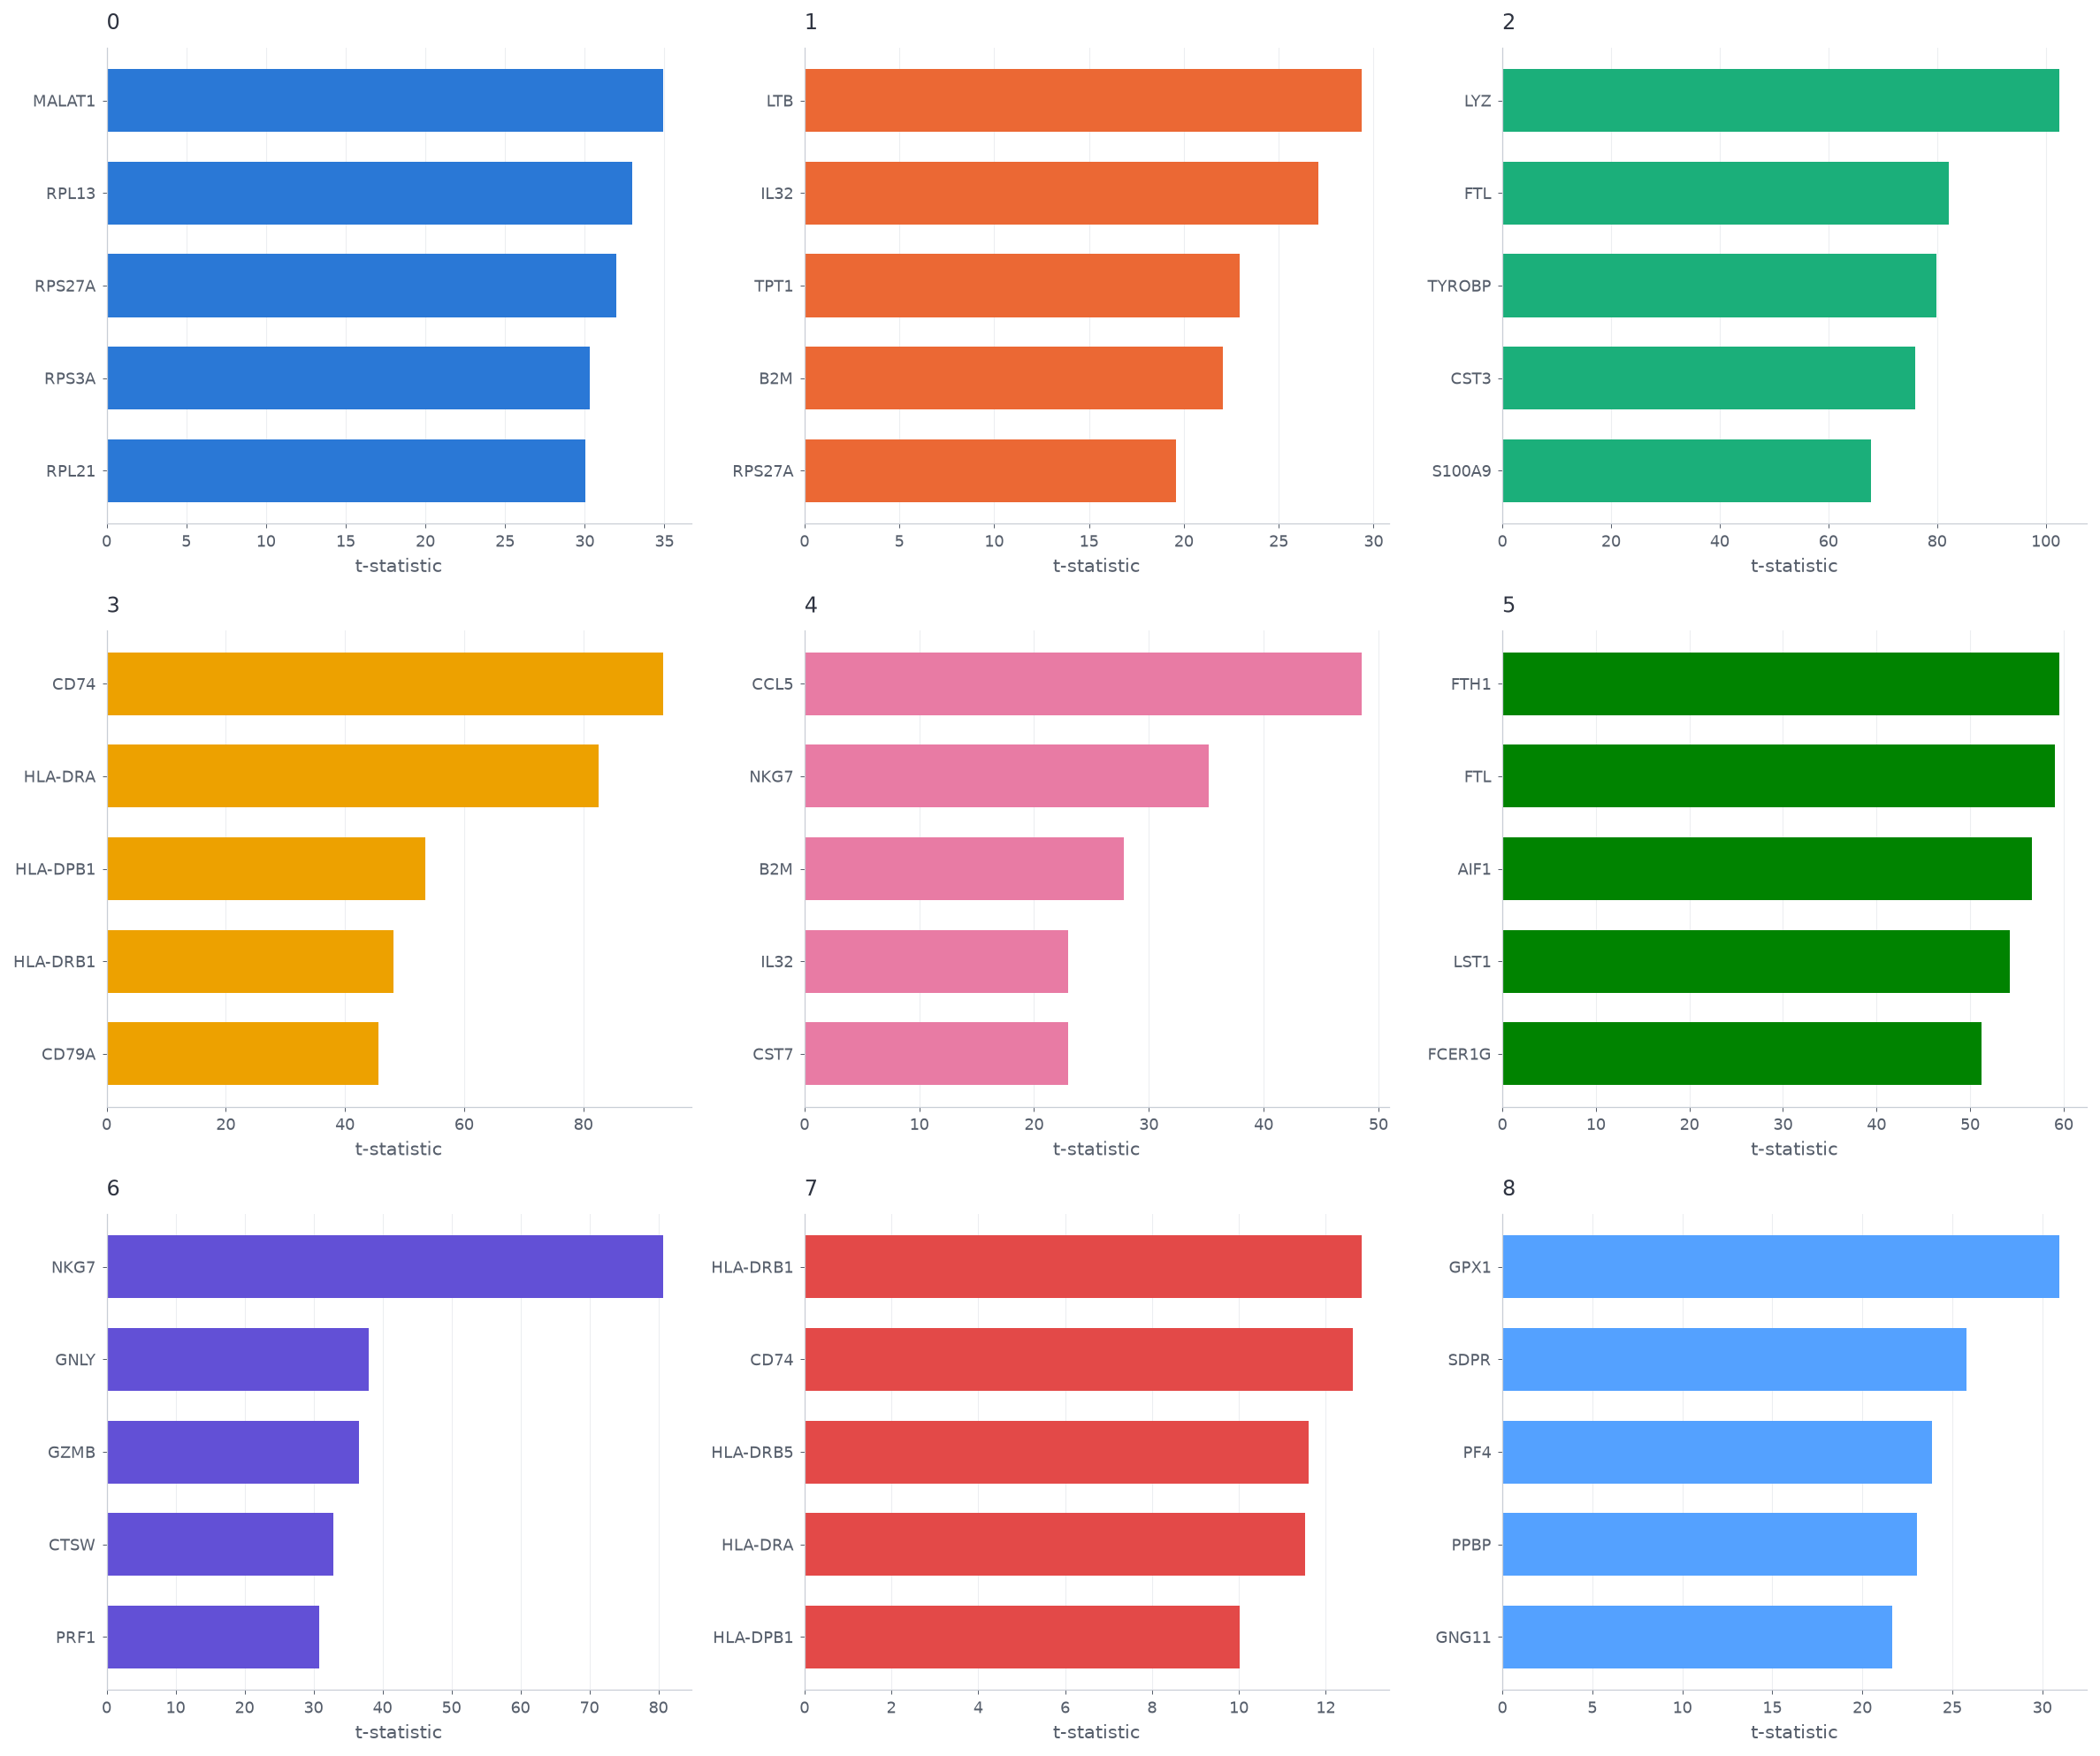

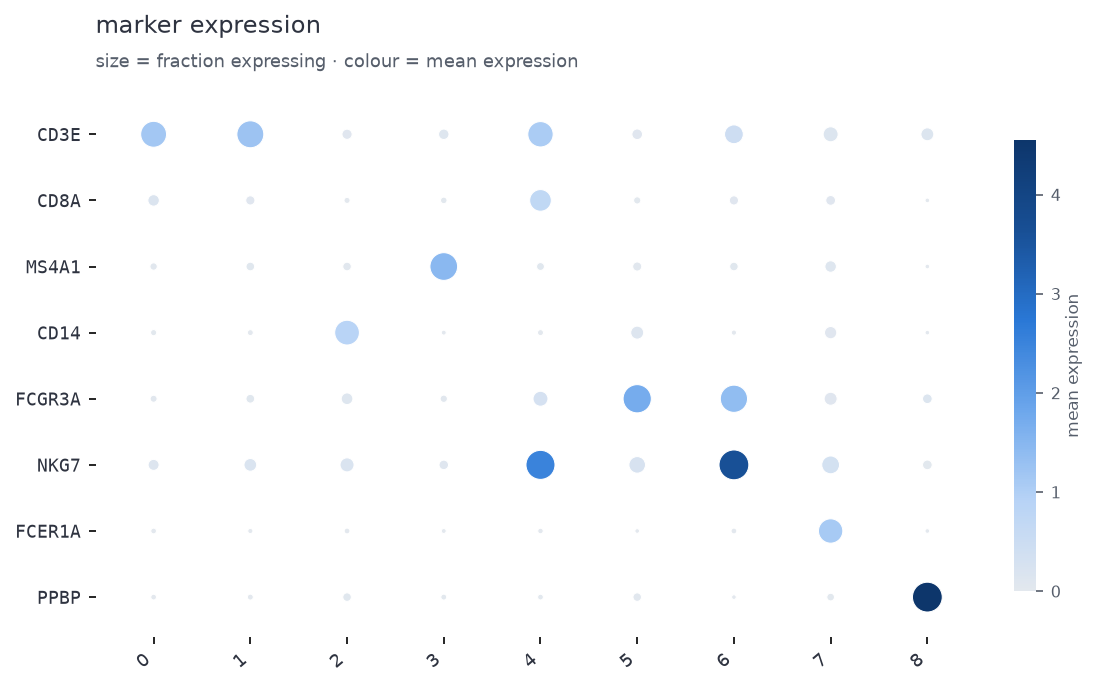

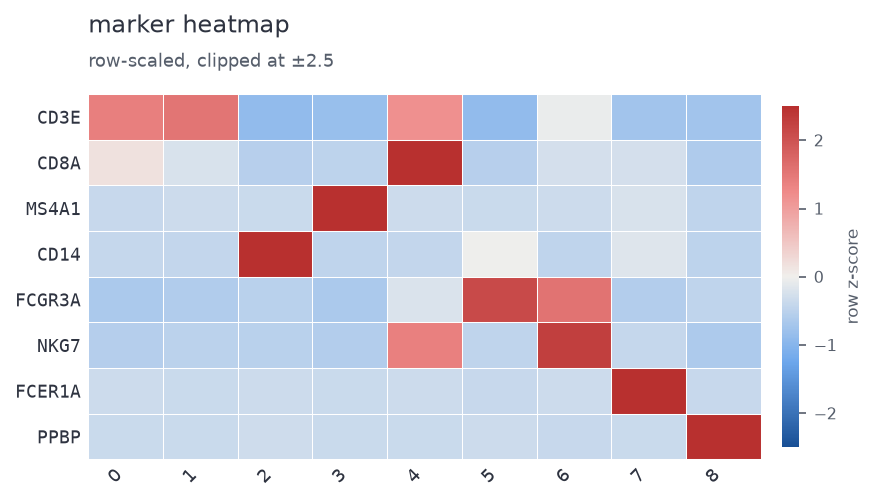

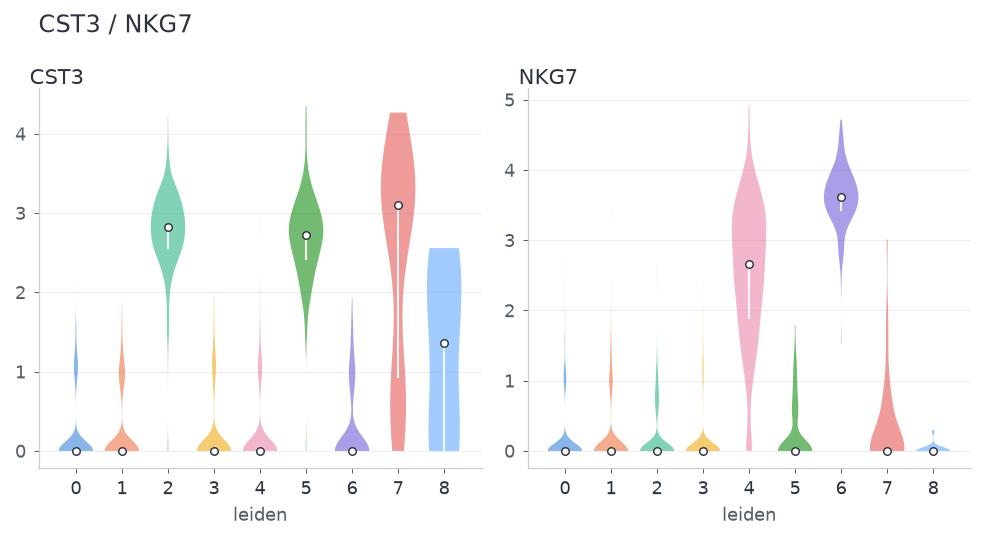

<Axes: title={'left': 'CST3 / NKG7'}, xlabel='leiden', ylabel='CST3'>

In [16]:
ps.pl.rank_genes_groups(adata, n_genes=5)
panel = ["CD3E", "CD8A", "MS4A1", "CD14", "FCGR3A", "NKG7", "FCER1A", "PPBP"]
ps.pl.dotplot(adata, panel, groupby="leiden")
ps.pl.heatmap(adata, panel, groupby="leiden")
ps.pl.violin(adata, ["CST3", "NKG7"], groupby="leiden")

T memory cells         1141
Dendritic cells         501
B cells naive           328
NK cells                301
Monocytes               171
Gamma delta T cells     152
Megakaryocytes           12
Name: count, dtype: int64


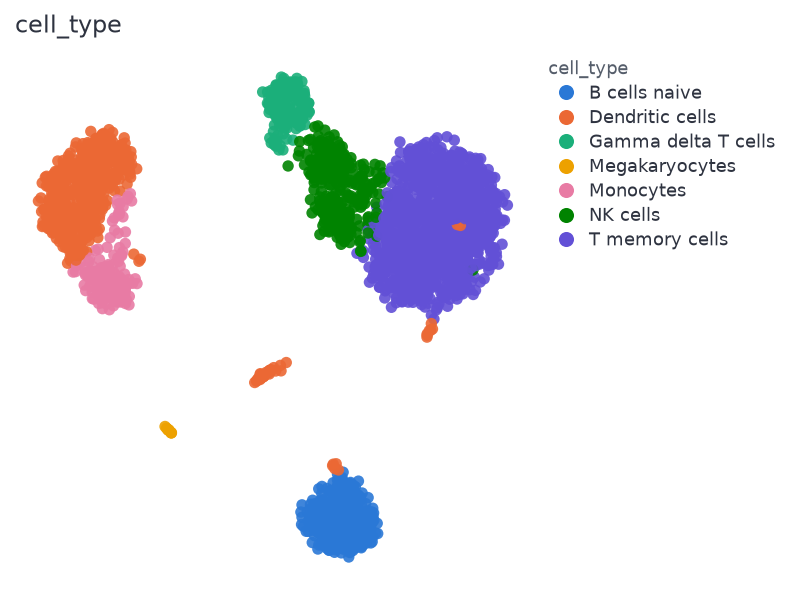

<Axes: title={'left': 'cell_type'}>

In [17]:
ps.tl.score_genes(adata, ["CD3E", "CD8A", "IL32"], score_name="t_cell_score")   # genes still in the data
ps.tl.auto_annotate(adata, "leiden", tissue="immune")
print(pd.Series(np.asarray(adata.obs["cell_type"])).value_counts().head(8))
ps.pl.umap(adata, color="cell_type")

cluster 2 split into 3 parts


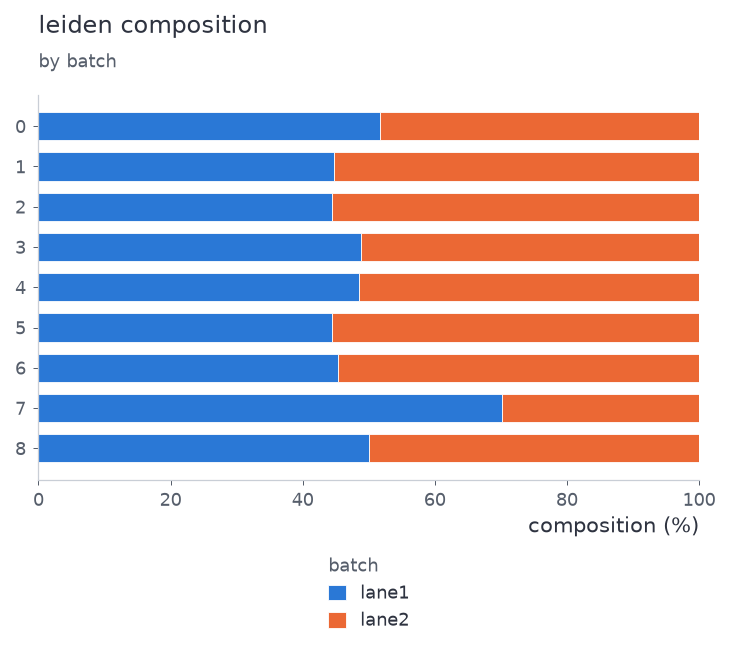

<Axes: title={'left': 'leiden composition'}, xlabel='composition (%)'>

In [18]:
ps.tl.annotate(adata, {"0": "first cluster", "1": "second cluster"}, key_added="by_hand",
               unassigned="other")
ps.tl.merge_clusters(adata, [["0", "1"]], key_added="merged")
parts = ps.tl.subcluster(adata, "2", resolution=0.5, key_added="split")
print("cluster 2 split into", parts, "parts")
ps.pl.stacked_bar(adata, groupby="leiden", color_by="batch")

In [19]:
from polariseq import markers
immune = markers.get_tissue_markers("immune")
print(len(immune), "immune cell types, e.g.", list(immune)[:4])

14 immune cell types, e.g. ['CD4 T cell', 'CD8 T cell', 'Regulatory T cell', 'B cell']


## 8. Comparing conditions

**`ps.tl.compare_conditions(adata, condition_key, reference, groupby=, sample_key=)`** compares
conditions within each cell type; with `sample_key` (the donor) cells are summed per donor and tested
as bulk samples, as edgeR and limma do. **`ps.get.pseudobulk`** gives those sums for DESeq2 or R.
PBMC 3k has one condition, so the labels below are made up and nothing should come out significant;
`examples/05_comparing_conditions.py` runs this on a real interferon experiment. The warning names
the clusters too small to compare (a donor needs `min_cells` cells of a cluster in each condition).

0 significant of 1,825 tests (expected: about none)


<cell>:3: UserWarning: not compared: 7: no sample of the reference condition; 8: no sample of the reference condition
  res = ps.tl.compare_conditions(adata, "condition", "ctrl", groupby="leiden", sample_key="donor")


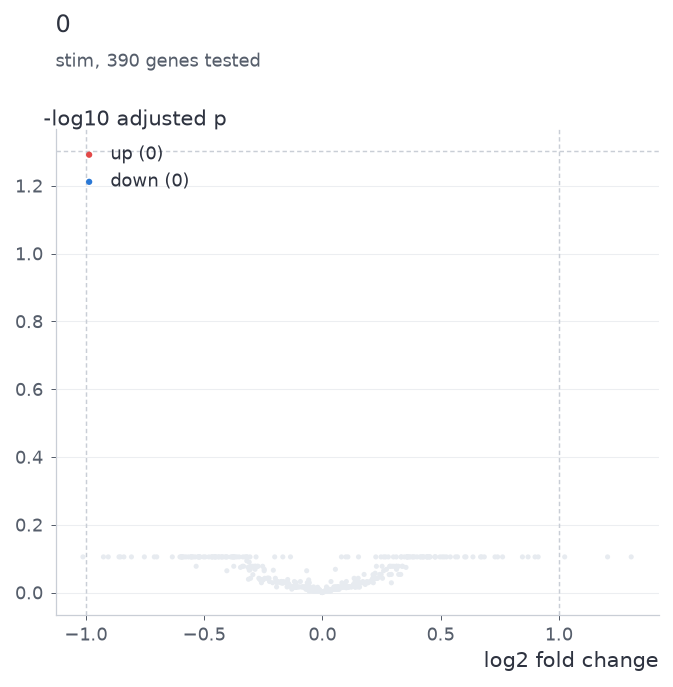

(71, 1503)

In [20]:
adata.obs["condition"] = pd.Categorical(rng.choice(["ctrl", "stim"], adata.n_obs))
adata.obs["donor"] = pd.Categorical(rng.choice(["d1", "d2", "d3", "d4"], adata.n_obs))
res = ps.tl.compare_conditions(adata, "condition", "ctrl", groupby="leiden", sample_key="donor")
print(f"{(res['adj_p_value'] < 0.05).sum()} significant of {len(res):,} tests (expected: about none)")
ps.pl.volcano(res, group="0")
pb = ps.get.pseudobulk(adata, "donor", groupby="leiden", condition_key="condition")
pb.shape

## 9. Several analyses, and how far they agree

**`adata.from_counts(name)`** starts a new analysis of the same cells from their raw counts, keeping
the cells' own annotations (QC, doublet scores, your columns) and its results in its own folder.
**`ps.tl.compare_analyses`** measures agreement (adjusted Rand index) between every pair, against
given labels, and, with `seeds=`, each analysis against itself under other seeds: the run-to-run
variation a difference should exceed.

In [21]:
other = adata.from_counts("hvg800_res0.6")
ps.pp.normalize_total(other)
ps.pp.log1p(other)
ps.pp.highly_variable_genes(other, n_top_genes=800, subset=True)
ps.pp.renormalize(other)
ps.pp.pca(other, n_components=30, scale=True, seed=0)
ps.pp.neighbors(other, seed=0)
ps.tl.leiden(other, resolution=0.6, seed=0)
cmp = ps.tl.compare_analyses({"main": adata, "hvg800_res0.6": other}, labels="cell_type", seeds=2)
cmp

Comparison of 2 analyses by obs['leiden'] on 2,606 shared cells

clusters:
main             9
hvg800_res0.6    5

adjusted Rand index:
                main  hvg800_res0.6
main           1.000          0.589
hvg800_res0.6  0.589          1.000

agreement with itself under other seeds (ARI):
main             0.808
hvg800_res0.6    0.997

agreement with the labels:
                 ari    nmi  clusters
main           0.705  0.896         9
hvg800_res0.6  0.855  0.841         5

              cells match  match_cells  shared_cells   jaccard
main cluster                                                  
0               635     0         1161           630  0.540309
1               506     0         1161           498  0.426005
2               454     1          659           454  0.688923
3               328     3          331           328  0.990937
4               301     2          443           271  0.572939
5               171     1          659           171  0.259484
6               152     2          443           152  0.343115
7                47     1          659            33  0.049034


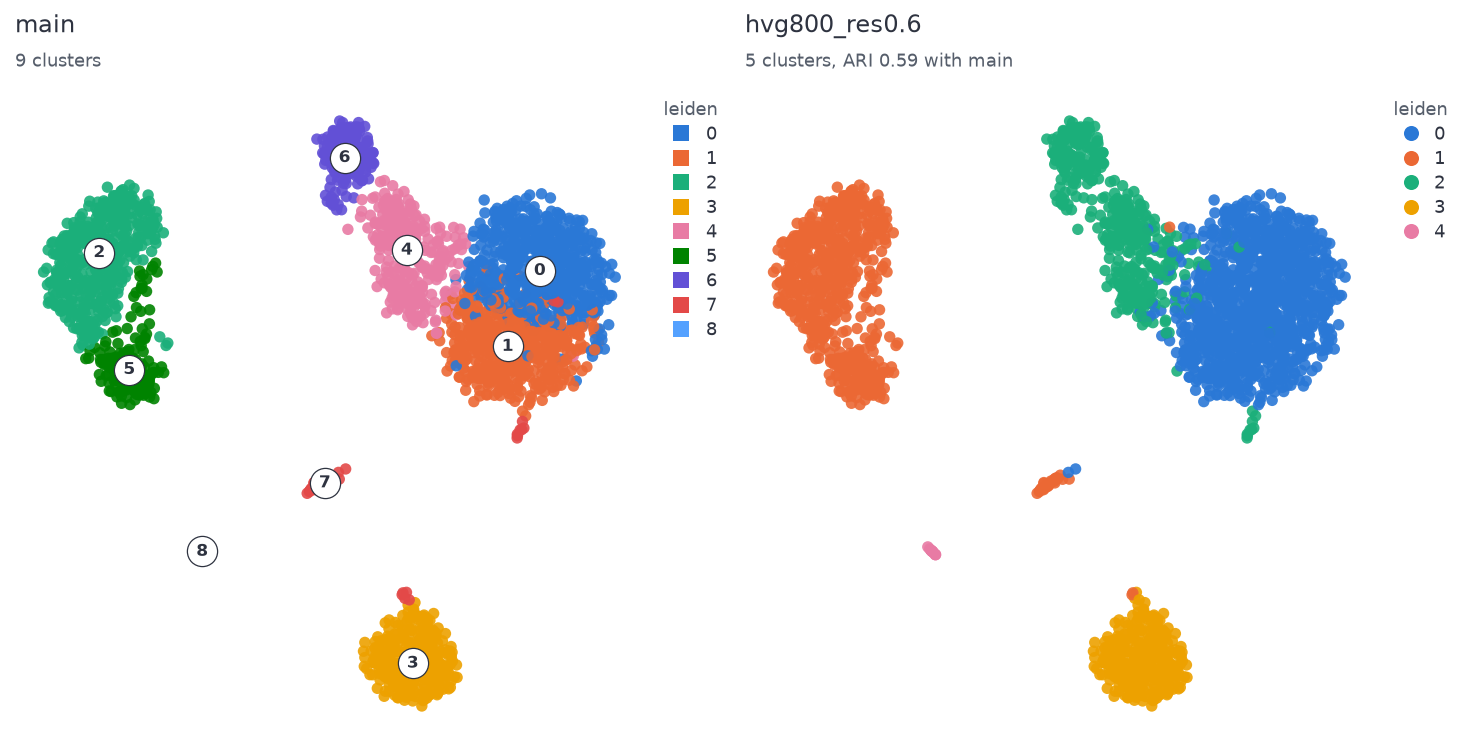

[<Axes: title={'left': 'main'}>, <Axes: title={'left': 'hvg800_res0.6'}>]

In [22]:
print(cmp.matches[("main", "hvg800_res0.6")].head(8).to_string())
ps.pl.compare_analyses({"main": adata, "hvg800_res0.6": other})

## 10. Saving, loading, exporting

**`adata.save(name)`** keeps the analysis in the project; **`ps.load(project, name)`** opens it again,
the matrix rebuilt from the source file (identical to the last bit), results linked, not copied.
If the source file moves, loading says where it was expected (`relink=` gives the new place).
**`adata.write_h5ad(path, counts=True)`** writes an `.h5ad` for Scanpy, cellxgene or R; **`to_anndata()`**
hands the analysis to Scanpy in memory (needs the `anndata` package).

In [23]:
adata.save("main", overwrite=True)
again = ps.load(proj.path, "main")
print(again.shape, "| clusters identical:", np.array_equal(np.asarray(again.obs["leiden"]), np.asarray(adata.obs["leiden"])))
print({k: f"{v / 1e6:.1f} MB" for k, v in proj.status().items() if v})
out = adata.write_h5ad(ROOT / "examples" / "output" / "pbmc3k_notebook.h5ad", counts=True)
print("written", out.name, f"{out.stat().st_size / 1e6:.1f} MB")
try:
    import anndata  # noqa: F401
    print(adata.to_anndata())
except ImportError:
    print("to_anndata needs the anndata package (pip install 'polariseq[anndata]')")

(2606, 1503) | clusters identical: True
{'states/main': '2.4 MB', 'runs/pbmc3k/results': '2.3 MB', 'runs/pbmc3k/analyses/hvg800_res0.6': '1.1 MB', 'runs/pbmc3k_ooc/matrix': '3.9 MB'}
written pbmc3k_notebook.h5ad 10.1 MB


AnnData object with n_obs × n_vars = 2606 × 1503
    obs: 'n_counts', 'n_genes', 'pct_counts_mt', 'doublet_score', 'predicted_doublet', 'batch', 'leiden', 'paris', 'dpt_pseudotime', 't_cell_score', 'cell_type', 'by_hand', 'merged', 'split', 'condition', 'donor'
    var: 'n_cells', 'total_counts', 'mean_counts', 'means', 'dispersions', 'dispersions_norm', 'highly_variable', 'included'
    uns: 'scrublet', 'normalize', 'hvg', 'log1p', 'pca', 'harmony', 'neighbors', 'leiden', 'umap', 'paris', 'paga', 'dpt', 'rank_genes_groups', 'rank_genes_groups_params', 'annotation', 'curation', 'compare_conditions'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    obsp: 'distances', 'connectivities'
    layers: None (.X)


## 11. Out of core, and the one-call pipeline

The same code runs out of core: the counts are copied once into the project and every step reads
them in blocks within the budget; `adata.X` is then a `DiskMatrix`. **`ps.process_diskbacked`** runs
quality control through Leiden in one call, always out of core.

In [24]:
ooc = ps.read_h5ad(str(src), mode="out-of-core", name="pbmc3k_ooc")
ps.pp.calculate_qc_metrics(ooc)
ps.pp.filter_cells(ooc, min_genes=200)
ps.pp.normalize_total(ooc)
ps.pp.log1p(ooc)
print(ooc.mode, type(ooc.X).__name__, ooc.X.shape)
one_call = ps.process_diskbacked(str(src), min_genes=200, min_cells=3, n_hvg=1500, n_pcs=30)
print(one_call.uns["leiden"]["n_communities"], "clusters from process_diskbacked")

[polariseq] pbmc3k_ooc: out of core (planned peak 0.6 GB of 4.0 GB); counts reused in ~/polariseq/examples/output/project_notebook/runs/pbmc3k_ooc/matrix (0.0 GB, 0.0 s), 19,456 cells per block
Filtered out 0 cells (2,700 remaining)
out-of-core DiskMatrix (2700, 32738)
[disk-backed] ~/polariseq/examples/output/project_notebook/data/pbmc3k.h5ad: 0.0 GB file, spilling to ~/polariseq/examples/output/project_notebook/scratch/
[disk-backed] plan: 19,456-row blocks, predicted peak 0.48 GB of 4.0 GB budget (floor 0.34 GB)


[disk-backed] spill + QC + normalize + log1p + HVG + PCA: 0.8s (2,700 of 2,700 cells × 13,714 of 32,738 genes, 2,286,884 nnz)
[disk-backed] neighbors + leiden on the embedding...
[disk-backed] done: 9 clusters
9 clusters from process_diskbacked


## 12. Figures for a whole analysis, themes, errors

**`ps.pl.overview`** writes the standard figures of an analysis to a folder. **`set_theme`**
switches the look (`paper`, `notebook`, `talk`, `dark`, `print`); **`categorical_palette`** gives the
colours used for groups. Errors name what is wrong and what to do.

['qc', 'pca', 'clusters', 'umap', 'umap_cell_type', 'figure_data']
['#2a78d6', '#eb6834', '#1baf7a', '#eda100']


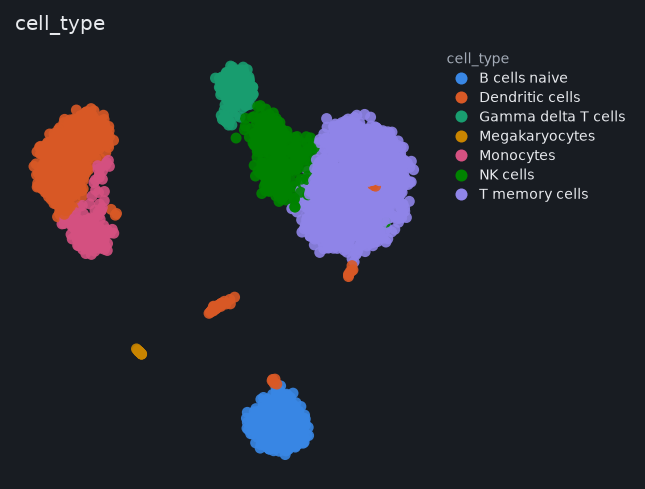

In [25]:
files = ps.pl.overview(adata, out=str(ROOT / "examples" / "output" / "overview_notebook"),
                       color_by=["cell_type"], qc_before=qc_before)
print(list(files))
print(ps.pl.categorical_palette(4))
ps.pl.set_theme("dark")
ps.pl.umap(adata, color="cell_type")
ps.pl.set_theme("notebook")

In [26]:
for mistake in (lambda: ps.tl.compare_conditions(adata, "conditon", "ctrl"),
                lambda: ps.pp.highly_variable_genes(adata, n_top_genes=500, include=["CD19X"]),
                lambda: ps.read_h5ad("pbmc3k.h5"),):
    try:
        mistake()
    except Exception as e:
        print(f"{type(e).__name__}: {e}\n")

InputError: compare_conditions: condition_key='conditon' is not a column of adata.obs. Did you mean 'condition'? Columns: 'n_counts', 'n_genes', 'pct_counts_mt', 'doublet_score', 'predicted_doublet', 'batch', 'leiden', 'paris', 'dpt_pseudotime', 't_cell_score', 'cell_type', 'by_hand', ... (16 in all).

InputError: include: 1 of the 1 genes asked for are not among this analysis's 1,503 genes:
  CD19X: not in the data. Did you mean 'CD19' or 'CDK19' or 'CD9'?
Genes are matched by their exact name in var_names (for example 'CPSF3L', 'MRPL20', 'C1orf86').

FileNotFoundError: read_h5ad: no file pbmc3k.h5 (looked in ~/polariseq/notebooks)

